# Dataset Information

## Glass Identification Dataset

Conjunto de dados de classificação multiclasse com 214 amostras de vidro, cada uma descrita por seu índice de refração e pela composição química. O objetivo é prever o tipo de vidro a partir dessas medidas.

O problema vem da ciência forense: vidro deixado em uma cena de crime pode servir de evidência, desde que seja identificado corretamente. Saber se um fragmento veio de uma janela de prédio, de um farol de carro ou de um recipiente ajuda a ligar suspeitos ao local.

Características gerais
Item	Valor
Amostras	214
Atributos preditivos	9 (todos numéricos contínuos)
Atributo-alvo	Tipo de vidro (6 classes presentes)
Valores ausentes	Nenhum
Tarefa	Classificação
Atributos
##	Atributo	Descrição
1.	    Id	Identificador da amostra (1 a 214).
2.	    RI	Índice de refração
3.	    Na	Sódio
4.	    Mg	Magnésio
5.	    Al	Alumínio
6.	    Si	Silício
7.	    K	Potássio
8.	    Ca	Cálcio
9.	    Ba	Bário
10.	    Fe	Ferro
11.	    Type	Tipo de vidro (classe-alvo)

Os atributos de 3 a 10 são dados em percentual em peso do óxido correspondente (por exemplo, o Na representa Na₂O).

## Classe Alvo
Esta pode ser de 6 tipos:

Código  |   Tipo de vidro   |   Amostras
1.	    Janela de construção, float	
2.	    Janela de construção, não float	
3.	    Janela de veículo, float	
5.	    Recipientes	
6.	    Louça de mesa	
7. 	    Faróis	

Fonte: https://archive.ics.uci.edu/dataset/42/glass+identification


## importanto o dataset

In [30]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Carregamento do dataset
glass_identification = fetch_ucirepo(id=42)

# Separação das features (X) e da variável alvo (y)
X = glass_identification.data.features
y = glass_identification.data.targets.squeeze()

# Visualização dos dados
display(X)
display(y)

# Verificação de valores ausentes
print("Total de valores ausentes nas features:", X.isnull().sum().sum())
print("Total de valores ausentes na variável alvo:", y.isnull().sum())

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0
...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0


0      1
1      1
2      1
3      1
4      1
      ..
209    7
210    7
211    7
212    7
213    7
Name: Type_of_glass, Length: 214, dtype: int64

Total de valores ausentes nas features: 0
Total de valores ausentes na variável alvo: 0


## Pré-processamento dos dados

Antes do treinamento dos modelos, foi realizada a preparação do conjunto de dados. A variável `Type`, correspondente ao tipo de vidro, foi definida como variável alvo (`y`), enquanto as demais colunas foram utilizadas como características de entrada (`X`).

Foi verificada a presença de valores ausentes no conjunto de dados e não foram encontrados valores nulos, portanto não foi necessário realizar procedimentos de preenchimento ou remoção de dados.

Também não foi necessária a aplicação de técnicas de codificação, como One-Hot Encoding ou Label Encoding, nas características de entrada, pois todas as features utilizadas pelos modelos são numéricas.

O conjunto de dados foi dividido em **80% para treinamento e 20% para teste**. Foi utilizado o parâmetro `stratify=y` para preservar, tanto quanto possível, a proporção das diferentes classes nos conjuntos de treinamento e teste. Também foi definido `random_state=42` para permitir a reprodução dos experimentos.

## Partição dos dados em treino e teste

### Holdout 80/20

In [32]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Amostras de treinamento:", len(X_tr))
print("Amostras de teste:", len(X_te))

Amostras de treinamento: 171
Amostras de teste: 43


## Árvore de Decisão

In [18]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
import graphviz

# Parâmetros testados pelo GridSearch
grade_arvore = {
    "max_depth": [3, 4, 5, None],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

# Busca pelos melhores hiperparâmetros
busca_arvore = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    grade_arvore,
    cv=5,
    scoring="f1_macro"
)

busca_arvore.fit(X_tr, y_tr)

# Melhor árvore encontrada
modelo_arvore = busca_arvore.best_estimator_

print("Melhores parâmetros:")
print(busca_arvore.best_params_)

# Previsões
pred_arvore = modelo_arvore.predict(X_te)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_te,
        pred_arvore,
        zero_division=0
    )
)

Melhores parâmetros:
{'class_weight': 'balanced', 'max_depth': 4, 'min_samples_leaf': 1}

Relatório de classificação:
              precision    recall  f1-score   support

           1       0.75      0.43      0.55        14
           2       0.62      0.33      0.43        15
           3       0.25      1.00      0.40         3
           5       0.50      0.67      0.57         3
           6       0.67      1.00      0.80         2
           7       0.50      0.67      0.57         6

    accuracy                           0.51        43
   macro avg       0.55      0.68      0.55        43
weighted avg       0.62      0.51      0.51        43



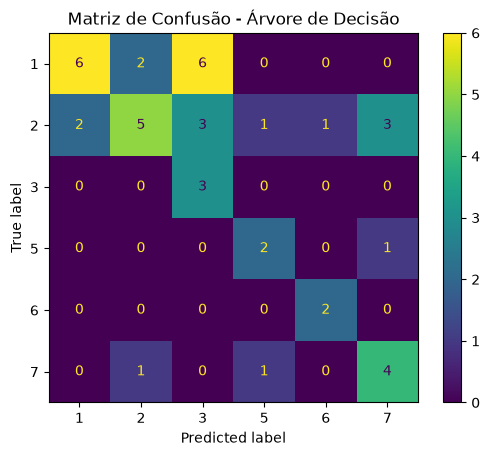

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_te,
    pred_arvore
)

plt.title("Matriz de Confusão - Árvore de Decisão")
plt.show()

### Matriz de Confusão

A matriz de confusão permite analisar o desempenho da Árvore de Decisão individualmente para cada classe. Os valores da diagonal principal representam classificações corretas, enquanto os valores fora da diagonal indicam casos em que o modelo confundiu uma classe com outra.

Essa análise complementa as métricas apresentadas anteriormente, permitindo identificar em quais classes o modelo apresenta maior facilidade ou dificuldade de classificação.

In [20]:
import pandas as pd

importancias_arvore = pd.Series(
    modelo_arvore.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Importância das features:")
display(importancias_arvore)

Importância das features:


Mg    2.306497e-01
Ba    2.129288e-01
K     1.946782e-01
Na    1.392903e-01
RI    9.003392e-02
Ca    8.498780e-02
Al    4.743124e-02
Si    5.248945e-17
Fe    0.000000e+00
dtype: float64

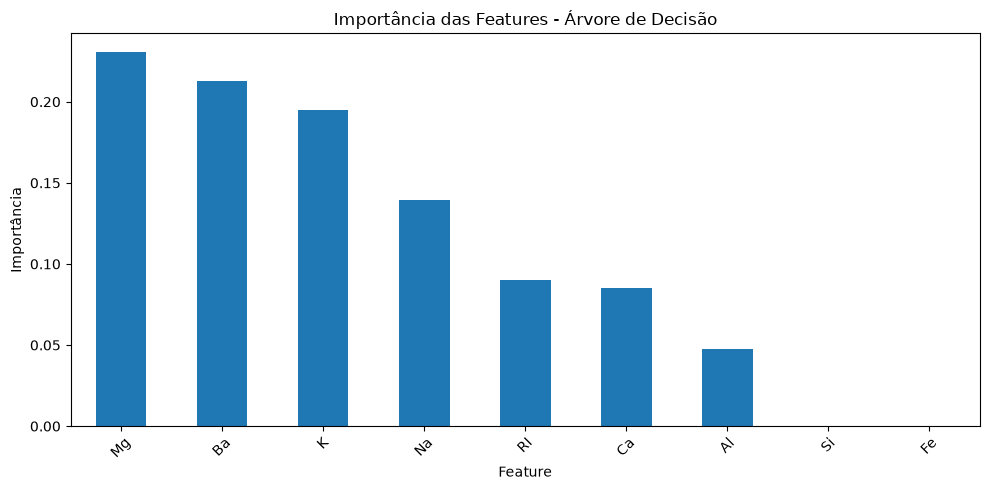

In [21]:
plt.figure(figsize=(10, 5))

importancias_arvore.plot(kind="bar")

plt.title("Importância das Features - Árvore de Decisão")
plt.xlabel("Feature")
plt.ylabel("Importância")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Interpretação da Importância das Features

A análise da importância das features mostra que **Mg (23,06%)**, **Ba (21,29%)** e **K (19,47%)** foram as características de maior influência na Árvore de Decisão treinada. Juntas, essas três variáveis representam aproximadamente **63,8% da importância total** atribuída pelo modelo.

Em seguida aparecem **Na (13,93%)**, **RI (9,00%)**, **Ca (8,50%)** e **Al (4,74%)**, que também contribuíram para as decisões da árvore, porém com menor influência.

Por outro lado, **Si apresentou importância praticamente nula e Fe apresentou importância igual a zero**, indicando que essas características não tiveram participação relevante nas divisões realizadas pela árvore treinada.

Esses resultados permitem identificar quais características tiveram maior influência global sobre as decisões do modelo. É importante destacar que essa importância se refere especificamente à Árvore de Decisão treinada neste experimento e não significa necessariamente que essas sejam as características mais importantes para todos os modelos de classificação.

### Interpretabilidade da Árvore de Decisão

A Árvore de Decisão é considerada um modelo de fácil interpretação porque sua estrutura permite visualizar diretamente as regras utilizadas para realizar uma classificação. Cada nó interno representa uma decisão baseada no valor de uma determinada feature, enquanto os ramos representam os possíveis caminhos resultantes dessa decisão.

Dessa forma, é possível acompanhar o processo desde o nó raiz até uma folha e identificar quais características e condições levaram o modelo a determinada classificação. Além disso, a análise da importância das features permite compreender globalmente quais variáveis tiveram maior influência nas decisões do modelo.

Entretanto, essa facilidade de interpretação pode diminuir em árvores muito profundas e complexas, devido ao aumento da quantidade de regras e caminhos possíveis.

In [22]:
import numpy as np

# Seleciona uma amostra que foi classificada corretamente
indices_corretos = np.where(pred_arvore == y_te.to_numpy())[0]

indice = indices_corretos[0]

amostra_arvore = X_te.iloc[[indice]]
classe_real = y_te.iloc[indice]
classe_prevista = pred_arvore[indice]

print("Índice da amostra no conjunto de teste:", indice)
print("Classe real:", classe_real)
print("Classe prevista:", classe_prevista)

display(amostra_arvore)

Índice da amostra no conjunto de teste: 0
Classe real: 7
Classe prevista: 7


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
208,1.5164,14.37,0.0,2.74,72.85,0.0,9.45,0.54,0.0


In [23]:
tree = modelo_arvore.tree_

node_indicator = modelo_arvore.decision_path(amostra_arvore)
leaf_id = modelo_arvore.apply(amostra_arvore)

feature = tree.feature
threshold = tree.threshold

node_index = node_indicator.indices[
    node_indicator.indptr[0]:node_indicator.indptr[1]
]

print("Caminho percorrido pela amostra:\n")

for node_id in node_index:

    if node_id == leaf_id[0]:
        print(f"Nó {node_id}: folha final")
        continue

    feature_name = X.columns[feature[node_id]]
    feature_value = amostra_arvore.iloc[0, feature[node_id]]
    limite = threshold[node_id]

    if feature_value <= limite:
        sinal = "<="
    else:
        sinal = ">"

    print(
        f"Nó {node_id}: "
        f"{feature_name} = {feature_value:.3f} "
        f"{sinal} {limite:.3f}"
    )

Caminho percorrido pela amostra:

Nó 0: Mg = 0.000 <= 2.695
Nó 1: K = 0.000 <= 0.125
Nó 2: Ba = 0.540 > 0.200
Nó 6: folha final


### Explicação de uma Previsão Individual

Para demonstrar como a Árvore de Decisão realiza uma classificação, foi analisada uma amostra do conjunto de teste que pertence à **classe 7** e foi corretamente classificada pelo modelo como **classe 7**.

O caminho percorrido pela amostra mostra de forma clara as regras utilizadas pelo modelo. Inicialmente, a árvore verificou a concentração de **Mg**, cujo valor era **0,000**, atendendo à condição `Mg ≤ 2,695`. Em seguida, foi analisada a concentração de **K**, também igual a **0,000**, atendendo à condição `K ≤ 0,125`. Por fim, a árvore avaliou **Ba**, que apresentava valor **0,540**, atendendo à condição `Ba > 0,200`.

Após essas três decisões, a amostra chegou ao **nó 6**, que corresponde a uma folha da árvore, resultando na classificação final como **classe 7**.

Esse exemplo demonstra a interpretabilidade local da Árvore de Decisão, pois é possível rastrear diretamente a sequência de condições utilizadas pelo modelo para produzir uma previsão específica. Nesse caso, as características **Mg, K e Ba** foram suficientes para conduzir a amostra até a classificação como classe 7.

## Naive Bayes

In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

modelo_nb = GaussianNB()
modelo_nb.fit(X_tr, y_tr)

pred_nb = modelo_nb.predict(X_te)

print("Relatório de classificação:")
print(classification_report(
    y_te,
    pred_nb,
    zero_division=0
))

Relatório de classificação:
              precision    recall  f1-score   support

           1       0.50      0.86      0.63        14
           2       0.40      0.13      0.20        15
           3       0.00      0.00      0.00         3
           5       0.50      0.33      0.40         3
           6       0.50      1.00      0.67         2
           7       0.83      0.83      0.83         6

    accuracy                           0.51        43
   macro avg       0.46      0.53      0.46        43
weighted avg       0.48      0.51      0.45        43



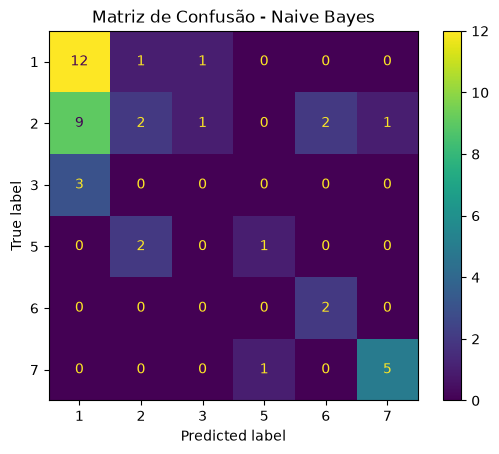

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_te,
    pred_nb
)

plt.title("Matriz de Confusão - Naive Bayes")
plt.show()

### Análise da Matriz de Confusão

A matriz de confusão mostra diferenças consideráveis no desempenho do Naive Bayes entre as classes. O modelo apresentou bom desempenho para a **classe 1**, classificando corretamente 12 das 14 amostras, e também para as **classes 6 e 7**, com 2 de 2 e 5 de 6 classificações corretas, respectivamente.

Por outro lado, o modelo apresentou maior dificuldade principalmente nas **classes 2 e 3**. Na classe 2, apenas 2 das 15 amostras foram classificadas corretamente, enquanto 9 foram incorretamente classificadas como classe 1. Para a classe 3, nenhuma das 3 amostras foi corretamente identificada, sendo todas classificadas como classe 1.

A classe 5 também apresentou dificuldade, com apenas 1 das 3 amostras classificada corretamente e as outras 2 classificadas como classe 2.

Os resultados indicam, portanto, uma tendência do modelo a confundir principalmente as classes **2 e 3 com a classe 1**. Isso demonstra a importância de analisar o desempenho por classe, pois a avaliação global do modelo pode ocultar dificuldades significativas na identificação de determinadas categorias.

In [26]:


print("Probabilidades das classes:")
display(pd.DataFrame({
    "classe": modelo_nb.classes_,
    "probabilidade": modelo_nb.class_prior_
}))

print("Médias das features por classe:")
display(pd.DataFrame(
    modelo_nb.theta_,
    index=modelo_nb.classes_,
    columns=X.columns
).round(3))

print("Variâncias das features por classe:")

display(pd.DataFrame(
    modelo_nb.var_,
    index=modelo_nb.classes_,
    columns=X.columns
).round(3))

Probabilidades das classes:


,classe,probabilidade
0,1,0.327485
1,2,0.356725
2,3,0.081871
3,5,0.058480
4,6,0.040936
5,7,0.134503


Médias das features por classe:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
1,1.519,13.201,3.558,1.156,72.633,0.460,8.816,0.004,0.066
2,1.519,13.058,3.100,1.410,72.584,0.533,9.021,0.061,0.086
3,1.518,13.439,3.545,1.222,72.324,0.412,8.806,0.011,0.062
5,1.519,12.711,1.006,2.026,72.478,1.210,10.086,0.244,0.079
6,1.518,14.761,1.117,1.300,73.091,0.000,9.614,0.000,0.000
7,1.518,14.457,0.540,2.087,72.942,0.325,8.536,1.035,0.013


Variâncias das features por classe:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
1,0.0,0.220,0.063,0.067,0.339,0.044,0.339,0.000,0.009
2,0.0,0.372,1.271,0.088,0.502,0.036,3.414,0.161,0.012
3,0.0,0.288,0.028,0.113,0.258,0.049,0.153,0.001,0.013
5,0.0,0.658,0.964,0.433,1.638,2.945,3.994,0.430,0.028
6,0.0,1.277,1.201,0.353,1.019,0.000,1.890,0.000,0.000
7,0.0,0.514,1.150,0.201,1.065,0.436,0.661,0.482,0.001


### Análise das Probabilidades, Médias e Variâncias

As probabilidades a priori mostram que as classes **2 (35,67%)** e **1 (32,75%)** são as mais frequentes no conjunto de treinamento.

No Gaussian Naive Bayes, as **médias e variâncias** são utilizadas para estimar a distribuição de cada feature em cada classe e calcular as probabilidades condicionais. Algumas características apresentam diferenças relevantes, como **Mg**, com médias maiores nas classes 1 e 3, e **Ba**, com média mais elevada na classe 7. As diferenças nas médias e na dispersão dos valores ajudam o modelo a distinguir as classes durante a classificação.

### Probabilidades Condicionais

O **Gaussian Naive Bayes** utiliza a média (`theta_`) e a variância (`var_`) de cada feature para estimar as probabilidades condicionais de cada classe.

Na classificação, essas probabilidades são combinadas com a probabilidade a priori das classes, e o modelo escolhe aquela com maior probabilidade posterior.

O método assume que as features são **condicionalmente independentes**, o que simplifica o modelo, mas pode ser uma limitação quando existem relações entre as características.

In [27]:
import numpy as np

# Seleciona uma amostra corretamente classificada
indices_corretos_nb = np.where(pred_nb == y_te.to_numpy())[0]

indice_nb = indices_corretos_nb[0]

amostra_nb = X_te.iloc[[indice_nb]]
classe_real_nb = y_te.iloc[indice_nb]
classe_prevista_nb = pred_nb[indice_nb]

print("Índice da amostra no conjunto de teste:", indice_nb)
print("Classe real:", classe_real_nb)
print("Classe prevista:", classe_prevista_nb)

display(amostra_nb)

print("Probabilidades previstas para cada classe:")

probabilidades_nb = pd.DataFrame({
    "classe": modelo_nb.classes_,
    "probabilidade": modelo_nb.predict_proba(amostra_nb)[0]
}).sort_values("probabilidade", ascending=False)

display(probabilidades_nb)

Índice da amostra no conjunto de teste: 0
Classe real: 7
Classe prevista: 7


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
208,1.5164,14.37,0.0,2.74,72.85,0.0,9.45,0.54,0.0


Probabilidades previstas para cada classe:


,classe,probabilidade
5,7,9.990614e-01
3,5,9.385789e-04
1,2,1.781342e-08
2,3,5.559860e-143
0,1,2.639372e-230
4,6,0.000000e+00


### Interpretação de uma Previsão Individual

A amostra analisada pertence à **classe 7** e foi corretamente classificada pelo Naive Bayes como classe 7, com aproximadamente **99,91% de probabilidade**. A segunda maior probabilidade foi atribuída à classe 5, com cerca de **0,094%**.

Esse resultado mostra que, considerando as probabilidades condicionais das features e a probabilidade a priori de cada classe, o modelo encontrou evidências muito mais fortes para a **classe 7**. Características da amostra, como **Mg = 0,00** e **Ba = 0,54**, também são coerentes com o perfil observado anteriormente para essa classe.

## KNN

### Normalização dos dados para o KNN

Como o KNN realiza suas classificações com base na distância entre as amostras, diferenças de escala entre as features podem fazer com que determinadas variáveis exerçam uma influência desproporcional no cálculo das distâncias.

Por esse motivo, foi utilizado o `StandardScaler` para padronizar as features antes da aplicação do KNN. A padronização foi incorporada a um `Pipeline`, garantindo que o ajuste do `StandardScaler` seja realizado utilizando os dados de treinamento e aplicado posteriormente aos dados de teste, evitando vazamento de informações do conjunto de teste durante o treinamento.

In [45]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report

# Pipeline com padronização dos dados e KNN
pipe = Pipeline([
    ("sc", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Hiperparâmetros que serão testados
grade = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

# Busca pelos melhores hiperparâmetros
busca = GridSearchCV(
    pipe,
    grade,
    cv=StratifiedKFold(
        5,
        shuffle=True,
        random_state=42
    ),
    scoring="f1_macro"
)

# Treinamento
modelo = busca.fit(X_tr, y_tr)

print("Melhores parâmetros:")
print(modelo.best_params_)

# Previsões no conjunto de teste
pred_knn = modelo.predict(X_te)

print("\nRelatório de classificação:")
print(
    classification_report(
        y_te,
        pred_knn,
        zero_division=0
    )
)

Melhores parâmetros:
{'knn__n_neighbors': 1, 'knn__p': 1, 'knn__weights': 'uniform'}

Relatório de classificação:
              precision    recall  f1-score   support

           1       0.75      0.64      0.69        14
           2       0.77      0.67      0.71        15
           3       0.40      0.67      0.50         3
           5       0.75      1.00      0.86         3
           6       0.67      1.00      0.80         2
           7       1.00      1.00      1.00         6

    accuracy                           0.74        43
   macro avg       0.72      0.83      0.76        43
weighted avg       0.76      0.74      0.75        43



In [46]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_predict
)
from sklearn.metrics import confusion_matrix

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=42
)

r = cross_validate(
    busca,
    X,
    y,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

print(*[
    f"{m}: {r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}"
    for m in ["accuracy", "f1_macro"]
])

pred_cv_knn = cross_val_predict(
    busca,
    X,
    y,
    cv=StratifiedKFold(
        5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1
)

print(
    classification_report(
        y,
        pred_cv_knn,
        zero_division=0
    )
)

print(confusion_matrix(y, pred_cv_knn))

accuracy: 0.729 ± 0.057 f1_macro: 0.694 ± 0.081
              precision    recall  f1-score   support

           1       0.69      0.81      0.75        70
           2       0.77      0.70      0.73        76
           3       0.46      0.35      0.40        17
           5       0.57      0.62      0.59        13
           6       0.80      0.89      0.84         9
           7       0.96      0.83      0.89        29

    accuracy                           0.73       214
   macro avg       0.71      0.70      0.70       214
weighted avg       0.73      0.73      0.73       214

[[57  8  5  0  0  0]
 [16 53  2  4  1  0]
 [ 9  2  6  0  0  0]
 [ 0  4  0  8  0  1]
 [ 0  1  0  0  8  0]
 [ 1  1  0  2  1 24]]


In [47]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
r = cross_validate(busca, X, y, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
print(*[f"{m}: {r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}" for m in ["accuracy", "f1_macro"]])

pred = cross_val_predict(busca, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
print(classification_report(y, pred, zero_division=0))
print(confusion_matrix(y, pred))

accuracy: 0.729 ± 0.057 f1_macro: 0.694 ± 0.081
              precision    recall  f1-score   support

           1       0.69      0.81      0.75        70
           2       0.77      0.70      0.73        76
           3       0.46      0.35      0.40        17
           5       0.57      0.62      0.59        13
           6       0.80      0.89      0.84         9
           7       0.96      0.83      0.89        29

    accuracy                           0.73       214
   macro avg       0.71      0.70      0.70       214
weighted avg       0.73      0.73      0.73       214

[[57  8  5  0  0  0]
 [16 53  2  4  1  0]
 [ 9  2  6  0  0  0]
 [ 0  4  0  8  0  1]
 [ 0  1  0  0  8  0]
 [ 1  1  0  2  1 24]]


In [48]:
# Interpretabilidade do KNN

melhor_knn = modelo.best_estimator_
amostra = X_te.iloc[[0]]

k = melhor_knn.named_steps["knn"].n_neighbors
peso = melhor_knn.named_steps["knn"].weights

p = melhor_knn.named_steps["knn"].p

amostra_escalada = melhor_knn.named_steps["sc"].transform(amostra)

distancias, indices = melhor_knn.named_steps["knn"].kneighbors(
    amostra_escalada,
    n_neighbors=k
)

classe_real = y_te.iloc[0]
classe_prevista = modelo.predict(amostra)[0]

print("Classe real:", classe_real)
print("Classe prevista:", classe_prevista)
print("Número de vizinhos (k):", k)
print("Tipo de peso:", peso)
print("Métrica p:", p)

print("\nAmostra analisada:")
print(amostra)

print("\nVizinhos mais próximos:")

for posicao, (indice, distancia) in enumerate(
    zip(indices[0], distancias[0]),
    start=1
):
    print(f"\nVizinho {posicao}")
    print("Índice no treino:", indice)
    print("Classe:", y_tr.iloc[indice])
    print("Distância:", distancia)
    print("Características:")
    print(X_tr.iloc[indice])

# Classes dos vizinhos
classes_vizinhos = y_tr.iloc[indices[0]]

print("\nClasses dos vizinhos:")
print(classes_vizinhos.values)

print("\nContagem das classes:")
print(classes_vizinhos.value_counts())

# Se estiver usando peso por distância, mostra também o peso de cada vizinho
if peso == "distance":
    pesos_vizinhos = 1 / (distancias[0] + 1e-10)

    print("\nPesos dos vizinhos:")
    for i, peso_vizinho in enumerate(pesos_vizinhos, start=1):
        print(f"Vizinho {i}: {peso_vizinho}")

# Resultado final
if classe_real == classe_prevista:
    print("\nResultado: previsão correta.")
else:
    print("\nResultado: previsão incorreta.")

Classe real: 7
Classe prevista: 7
Número de vizinhos (k): 1
Tipo de peso: uniform
Métrica p: 1

Amostra analisada:
         RI     Na   Mg    Al     Si    K    Ca    Ba   Fe
208  1.5164  14.37  0.0  2.74  72.85  0.0  9.45  0.54  0.0

Vizinhos mais próximos:

Vizinho 1
Índice no treino: 166
Classe: 7
Distância: 1.3854303585425982
Características:
RI     1.51531
Na    14.38000
Mg     0.00000
Al     2.66000
Si    73.10000
K      0.04000
Ca     9.08000
Ba     0.64000
Fe     0.00000
Name: 198, dtype: float64

Classes dos vizinhos:
[7]

Contagem das classes:
Type_of_glass
7    1
Name: count, dtype: int64

Resultado: previsão correta.


### Interpretabilidade do KNN com LIME

O KNN é mais difícil de interpretar diretamente, pois sua classificação é baseada na distância entre uma nova amostra e seus vizinhos, sem gerar regras explícitas como uma Árvore de Decisão.

Para complementar a análise dos vizinhos, foi utilizado o **LIME**, que permite explicar localmente uma previsão e identificar quais características contribuíram para a classificação de uma amostra específica.

In [49]:
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(
    training_data=X_tr.values,
    feature_names=X_tr.columns.tolist(),
    class_names=[str(c) for c in melhor_knn.classes_],
    mode="classification",
    random_state=42
)

In [ ]:
amostra_lime = amostra.iloc[0]

classe_prevista_lime = melhor_knn.predict(amostra)[0]

indice_classe_lime = list(melhor_knn.classes_).index(
    classe_prevista_lime
)

# O LIME envia os dados como NumPy array.
# Esta função converte novamente para DataFrame com os nomes
# das features antes de passar os dados ao Pipeline.
def predict_proba_lime(dados):
    dados_df = pd.DataFrame(
        dados,
        columns=X_tr.columns
    )
    return melhor_knn.predict_proba(dados_df)

explicacao_lime = explainer.explain_instance(
    data_row=amostra_lime.values,
    predict_fn=predict_proba_lime,
    labels=(indice_classe_lime,),
    num_features=len(X_tr.columns)
)

In [51]:
print("Classe explicada pelo LIME:", classe_prevista_lime)
print("\nContribuições das features segundo o LIME:")

for regra, contribuicao in explicacao_lime.as_list(
    label=indice_classe_lime
):
    print(f"{regra}: {contribuicao:.4f}")

Classe explicada pelo LIME: 7

Contribuições das features segundo o LIME:
Ba > 0.00: 0.2087
Na > 13.79: 0.0801
Al > 1.62: 0.0779
Mg <= 2.26: 0.0717
Fe <= 0.00: 0.0673
Ca > 9.16: -0.0454
RI <= 1.52: -0.0435
72.78 < Si <= 73.09: -0.0300
K <= 0.13: -0.0067


In [52]:
probabilidades_knn = melhor_knn.predict_proba(amostra)[0]

display(
    pd.DataFrame({
        "classe": melhor_knn.classes_,
        "probabilidade": probabilidades_knn
    }).sort_values(
        "probabilidade",
        ascending=False
    )
)

,classe,probabilidade
5,7,1.0
0,1,0.0
1,2,0.0
2,3,0.0
3,5,0.0
4,6,0.0


### Análise da Interpretabilidade do KNN

O KNN não possui regras explícitas de decisão, pois sua classificação é baseada na proximidade entre as amostras. Para auxiliar na interpretação, o LIME foi utilizado para identificar localmente quais características mais influenciaram a previsão analisada.

Para essa amostra, o KNN previu a **classe 7 com probabilidade 1,0**. Como o melhor modelo utiliza **k = 1**, a classificação é determinada pelo vizinho mais próximo, o que também explica a probabilidade concentrada em uma única classe.

A análise com LIME complementa essa interpretação ao mostrar a contribuição das características para a decisão, porém representa uma explicação **local**, válida para a amostra analisada e não necessariamente para todo o conjunto de dados.